In [1]:
import os
os.environ["PYOPENGL_PLATFORM"] = "osmesa"
os.environ["PYVISTA_OFF_SCREEN"] = "True"
os.environ["PYVISTA_USE_WGL"] = "True"
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '1' #Select the GPU Card
print('Process id: ',os.getpid())

# Importing necessary libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
#from sklearn.ensemble import ExtraTreesClassifier
#from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate
from sklearn.utils.class_weight import compute_class_weight


from sklearn import metrics
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import RocCurveDisplay
import shap

Process id:  3359704


In [2]:
# Load the Excel file
Macula_df = pd.read_excel("./Parameter_ONH.xlsx", engine="openpyxl")  # Specify engine for .xlsx files

# Display the first few rows
print(Macula_df.head(5))
print(Macula_df.columns.tolist())

      ID  OD_fovea  OD_I_S  OD_I_N  OD_I_I  OD_I_T  OD_O_S  OD_O_N  OD_O_I  \
0    N17       335     318     330     361     302     353     268     301   
1    N23       289     343     302     370     321     313     277     327   
2    N33       273     429     385     387     315     327     289     321   
3    N10       508     432     350     403     372     336     268     325   
4  43065       368     288     301     266     305     307     289     291   

   OD_O_T  ...  OS_I_T_Vol  OS_O_S_Vol  OS_O_N_Vol  OS_O_I_Vol  OS_O_T_Vol  \
0     317  ...        0.50        1.79        1.71        1.67        1.51   
1     306  ...        0.51        1.77        1.64        1.72        1.60   
2     323  ...        0.54        1.75        1.56        1.72        1.39   
3     305  ...        0.57        1.81        1.65        1.77        1.52   
4     296  ...        0.48        1.70        1.58        1.54        1.45   

   OS_Macula_volume  OS_Center_thickness  OS_Central_minimum_t

In [4]:
# X = iris_skl.data  # Features
# y = iris_skl.target  # Labels

Macula = np.array(Macula_df)
X = Macula[:,1:-1]  # Features
y = Macula[:,-1]  # Labels

y = np.array(y, dtype=np.uint8)
print(X)
print(y)

[[335 318 330 ... 325 192 381]
 [289 343 302 ... 320 234 381]
 [273 429 385 ... 488 246 564]
 ...
 [257 261 291 ... 298 161 308]
 [324 386 353 ... 309 205 383]
 [353 369 298 ... 446 252 472]]
[0 0 0 0 1 0 0 1 0 1 1 1 1 1 1 1 0 0 1 0 1 1 1 0 0 1 0 0 0 0 1 1 1 0 1 1 0
 1 0 1 1 1 0 1 0 0 1 0 1 0]


In [56]:
def Normalize(arr):
    # Compute min and max for each column
    col_min = arr.min(axis=0)  # Minimum of each column
    col_max = arr.max(axis=0)  # Maximum of each column
    
    # Avoid division by zero (if all values in a column are the same)
    col_range = col_max - col_min
    col_range[col_range == 0] = 1  # Prevent division by zero
    
    # Normalize using broadcasting
    normalized_arr = (arr - col_min) / col_range

    return normalized_arr

def Oversample(arr,num_samp):
    # Number of rows to sample
    num_samples = num_samp 
    
    # Randomly select row indices
    random_indices = np.random.choice(arr.shape[0], num_samples, replace=True)  # replace=True allows duplicates
    
    # Extract the selected rows
    random_rows = arr[random_indices]
    
    # Append the selected rows to the original array
    new_arr = np.vstack((arr, random_rows))
    
    return new_arr



def train_test_split_custom(X, y):
    X = Normalize(X)
    c_array_new = np.column_stack((X,y))

    # Extract the diagnosis column (last column)
    outcome = c_array_new[:, -1]

    c_array_new_0 = c_array_new[outcome == 0]  # Rows where species is 0
    c_array_new_1 = c_array_new[outcome == 1]  # Rows where species is 1

    np.random.shuffle(c_array_new_0)
    np.random.shuffle(c_array_new_1)

    # train test split
    split_len = int(0.7*len(c_array_new_0))
    c_array_new_0_train = c_array_new_0[0:split_len,:]
    c_array_new_0_test =  c_array_new_0[split_len:,:]

    split_len = int(0.7*len(c_array_new_1))
    c_array_new_1_train = c_array_new_1[0:split_len,:]
    c_array_new_1_test =  c_array_new_1[split_len:,:]


    # print(len(c_array_new_0_train),len(c_array_new_0_test))
    # print(len(c_array_new_1_train),len(c_array_new_1_test))

    # oversample
    if False:
        c_array_new_1_train = Oversample(c_array_new_1_train,len(c_array_new_0_train)-len(c_array_new_1_train))

        print(len(c_array_new_0_train),len(c_array_new_0_test))
        print(len(c_array_new_1_train),len(c_array_new_1_test))

    
    # combine
    train = np.concatenate((c_array_new_0_train,c_array_new_1_train), axis = 0)
    test  = np.concatenate((c_array_new_0_test, c_array_new_1_test), axis = 0)
    np.random.shuffle(train)
    np.random.shuffle(test)

    # split
    X_train = train[:,0:-1]
    y_train = train[:,-1]

    X_test = test[:,0:-1]
    y_test = test[:,-1]

    y_train = y_train.astype(int)
    y_test = y_test.astype(int)

    return X_train, X_test, y_train, y_test

In [57]:
feature_names = ['OD_fovea', 'OD_I_S', 'OD_I_N', 'OD_I_I', 'OD_I_T', 'OD_O_S', 'OD_O_N', 'OD_O_I', 'OD_O_T', 'OD_Vol ', 'OD_I_S_Vol', 'OD_I_N_Vol', 'OD_I_I_Vol', 'OD_I_T_Vol', 'OD_O_S_Vol', 'OD_O_N_Vol', 'OD_O_I_Vol', 'OD_O_T_Vol',
                 'OD_Macula_volume', 'OD_Center_thickness', 'OD_Central_minimum_thickness', 'OD_Central_maximum_thickness', 'OS_fovea', 'OS_I_S', 'OS_I_N', 'OS_I_I',
                 'OS_I_T', 'OS_O_S', 'OS_O_N', 'OS_O_I', 'OS_O_T', 'OS_Vol ', 'OS_I_S_Vol', 'OS_I_N_Vol', 'OS_I_I_Vol', 'OS_I_T_Vol', 'OS_O_S_Vol', 'OS_O_N_Vol', 'OS_O_I_Vol',
                 'OS_O_T_Vol', 'OS_Macula_volume', 'OS_Center_thickness', 'OS_Central_minimum_thickness', 'OS_Central_maximum_thickness']

In [1]:
# ================================
# Hyperparameter Grid
# ================================
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# ================================
# INITIALIZATION
# ================================
best_auc = 0
best_params = None

mean_fpr = np.linspace(0, 1, 100)
mean_recall = np.linspace(0, 1, 100)

tprs = []
aucs = []
accs = []

precisions = []
aps = []

threshold_list = []
best_params_list = []

# ================================
# Monte-Carlo Cross Validation
# ================================
for mci in range(5000):

    # ----------------------------
    # Train/Test Split
    # ----------------------------
    X_train, X_test, y_train, y_test = train_test_split_custom(X, y)

    # ----------------------------
    # Class weights
    # ----------------------------
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )

    class_weight_dict = {
        0: class_weights[0],
        1: class_weights[1]
    }

    # ----------------------------
    # Base Model
    # ----------------------------
    rf = RandomForestClassifier(
        class_weight=class_weight_dict,
        random_state=42
    )

    # ----------------------------
    # Nested Grid Search
    # ----------------------------
    grid = GridSearchCV(
        estimator=rf,
        param_grid=param_grid,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    best_params_list.append(grid.best_params_)

    # ----------------------------
    # Test Evaluation
    # ----------------------------
    y_pred_prob = best_model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

    roc_auc = auc(fpr, tpr)

    optimal_idx = np.argmax(tpr - fpr)
    optimal_thresh = thresholds[optimal_idx]

    y_pred = (y_pred_prob >= optimal_thresh).astype(int)

    acc = accuracy_score(y_test, y_pred)

    # ROC interpolation
    tpr_interp = np.interp(mean_fpr, fpr, tpr)
    tpr_interp[0] = 0

    tprs.append(tpr_interp)
    aucs.append(roc_auc)
    accs.append(acc)

    # Threshold
    threshold_list.append(optimal_thresh)

    # Precision-Recall
    precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)

    precision_interp = np.interp(
        mean_recall,
        recall[::-1],
        precision[::-1]
    )

    precisions.append(precision_interp)

    aps.append(
        average_precision_score(y_test, y_pred_prob)
    )

    # Best model
    if roc_auc > best_auc:
        best_auc = roc_auc
        best_params = grid.best_params_
        X_train_best = X_train.copy()
        X_test_best = X_test.copy()
        y_train_best = y_train.copy()
        y_test_best = y_test.copy()

# ================================
# POST PROCESSING
# ================================
tprs = np.array(tprs)
precisions = np.array(precisions)
threshold_array = np.array(threshold_list)

mean_tpr = tprs.mean(axis=0)
std_tpr = tprs.std(axis=0)
mean_tpr[-1] = 1

mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

mean_acc = np.mean(accs)
std_acc = np.std(accs)

mean_precision = precisions.mean(axis=0)
std_precision = precisions.std(axis=0)

mean_ap = np.mean(aps)
std_ap = np.std(aps)

print(f"Mean AUC : {mean_auc:.4f} ± {std_auc:.4f}")
print(f"Mean AP  : {mean_ap:.4f} ± {std_ap:.4f}")
print(f"Accuracy : {mean_acc:.4f} ± {std_acc:.4f}")

print("\nBest single split AUC:", best_auc)
print("Best hyperparameters:", best_params)

print("\nMedian Threshold:", np.median(threshold_array))
print("Mean Threshold:", np.mean(threshold_array))

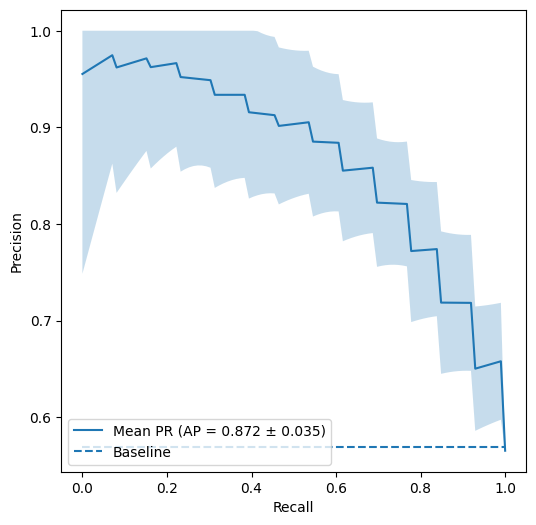

In [70]:
plt.figure(figsize=(6, 6))

plt.plot(
    mean_recall,
    mean_precision,
    label=f"Mean PR (AP = {mean_ap:.3f} ± {std_ap:.3f})"
)

lower = np.maximum(mean_precision - std_precision, 0)
upper = np.minimum(mean_precision + std_precision, 1)

plt.fill_between(
    mean_recall,
    lower,
    upper,
    alpha=0.25
)

# Baseline = positive class prevalence
baseline = np.mean(y)
plt.hlines(
    baseline, 0, 1,
    linestyles="dashed",
    label="Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
# Legend at top-right
plt.legend(loc="lower left")
#plt.tight_layout()
plt.show()


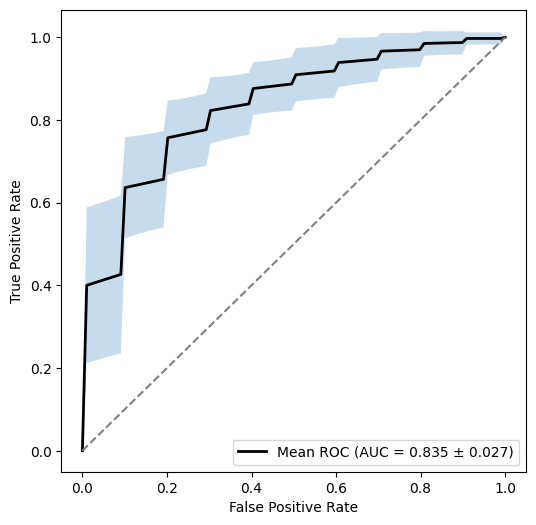

In [73]:

# roc_results = {}
# roc_data = {
#     "mean_fpr": mean_fpr,
#     "mean_tpr": mean_tpr,
#     "std_tpr": std_tpr,
#     "mean_auc": mean_auc,
#     "std_auc": std_auc
# }

# np.save("./ROC_RF.npy", roc_data)
plt.figure(figsize=(6, 6))

plt.plot(
    mean_fpr,
    mean_tpr,
    color='black',
    label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})',
    lw=2
)

plt.fill_between(
    mean_fpr,
    mean_tpr - std_tpr,
    mean_tpr + std_tpr,
    alpha=0.25
)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
#plt.title('Mean ROC Curve with Standard Deviation')
plt.legend(loc='lower right')
#plt.grid(True)
plt.show()

(44,)


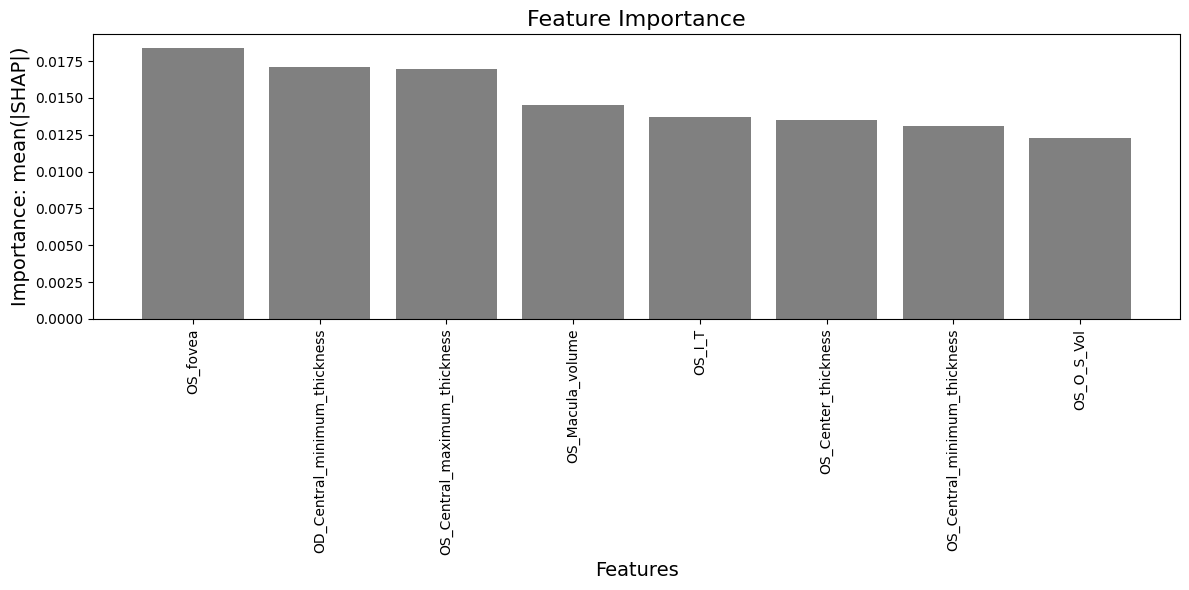

In [74]:
average_shap = []
for key in shap_values_dict:
    tarr = np.array(shap_values_dict[key]['SV'][:,:,0].values)
    average_shap.append(np.mean(np.abs(tarr),axis=0))
    
average_shap = np.array(average_shap)
finalmean = np.mean(average_shap, axis = 0)
print(np.shape(finalmean))

# Step 1: Combine arrays into a 2D array
combined_array = np.column_stack((feature_names, finalmean))

# Step 2: Sort by the second column (numbers) in descending order
sorted_array = combined_array[np.argsort(combined_array[:, 1].astype(float))[::-1]]

# Take top 5 most important features
top8 = sorted_array[:8]



# Plot
plt.figure(figsize=(12, 6), facecolor="none")
# plt.bar(col_keep[:-1], finalmean, color='red')
# plt.bar(sorted_array[:,0],np.round(np.array(sorted_array[:,1],dtype=np.float32), 4), color='gray')
plt.bar(top8[:, 0],np.round(top8[:, 1].astype(float), 4),color='gray')
plt.xlabel('Features', fontsize=14)
plt.ylabel('Importance: mean(|SHAP|)', fontsize=14)
plt.title('Feature Importance', fontsize=16)
plt.xticks(rotation=90, fontsize=10)
plt.tight_layout()
# plt.savefig('./SHAPFeatureImp.png')
plt.show()

In [75]:
# Recompute class weights on best training data
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_best),
    y=y_train_best
)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

# Train RF on best split
rf_best = RandomForestClassifier(
    class_weight=class_weight_dict,
    n_estimators=100,
    random_state=42
)

rf_best.fit(X_train_best, y_train_best)


RandomForestClassifier(class_weight={0: np.float64(1.1666666666666667),
                                     1: np.float64(0.875)},
                       random_state=42)

In [76]:
# Predict probabilities
y_test_prob = rf_best.predict_proba(X_test_best)[:, 1]

# Convert probabilities to class labels
y_test_pred = (y_test_prob >= 0.5).astype(int)

In [77]:
cm = confusion_matrix(y_test_best, y_test_pred)
print(cm)


[[ 4  6]
 [ 0 13]]


<Figure size 600x500 with 0 Axes>

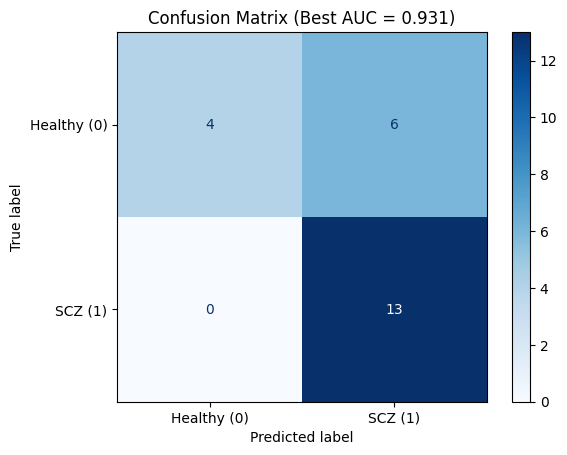

In [78]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy (0)", "SCZ (1)"]
)

plt.figure(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix (Best AUC = {best_auc:.3f})")
plt.show()
